In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('student-por.csv', sep=';')

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
# Select all columns except G3 as input features

X = df.drop(columns=['G3'])

# Convert categorical features into numerical features

X = pd.get_dummies(X, drop_first=True)

# Convert final grade into classification labels
# 1 = Pass, 0 = Fail

y = (df['G3'] >= 10).astype(int).to_numpy()

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

print("Number of Fail students:", np.sum(y == 0))
print("Number of Pass students:", np.sum(y == 1))

Shape of X: (649, 41)
Shape of y: (649,)
Number of Fail students: 100
Number of Pass students: 549


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=56,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 519
Testing samples: 130


In [5]:
classifier = DummyClassifier(
    strategy='most_frequent'
)

classifier.fit(X_train, y_train)

print("Baseline Classification model trained successfully!")

Baseline Classification model trained successfully!


In [6]:
predictions = classifier.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

precision = precision_score(
    y_test, predictions, zero_division=0
)

recall = recall_score(
    y_test, predictions, zero_division=0
)

f1 = f1_score(
    y_test, predictions, zero_division=0
)

print(f'Accuracy = {accuracy:.4f}')
print(f'Precision = {precision:.4f}')
print(f'Recall = {recall:.4f}')
print(f'F1 Score = {f1:.4f}')

Accuracy = 0.8462
Precision = 0.8462
Recall = 1.0000
F1 Score = 0.9167


In [7]:
print(classification_report(
    y_test,
    predictions,
    target_names=['Fail', 'Pass'],
    zero_division=0
))

              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00        20
        Pass       0.85      1.00      0.92       110

    accuracy                           0.85       130
   macro avg       0.42      0.50      0.46       130
weighted avg       0.72      0.85      0.78       130



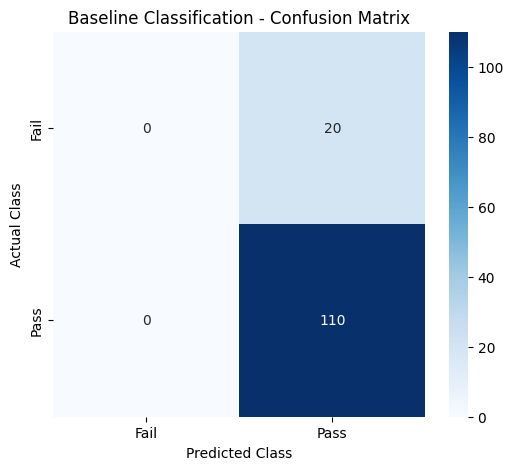

In [8]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.title('Baseline Classification - Confusion Matrix')

plt.show()

In [9]:
baseline_predictions = predictions